# PCA 2D des images

1. Chargement du dataframe via `src.features.dataset.create_dataframe`.
2. Tirage de `N = 1000` images aléatoires.
3. **PCA A** : sur les images passées par le pipeline de transformation (`build_transform`, `training=False`).
4. **PCA B** : sur les mêmes images brutes, sans aucune transformation (juste un redimensionnement au format carré, indispensable pour aplatir).
5. Pour chaque PCA : affichage des `N` images à leurs coordonnées dans le plan des 2 composantes, puis nuage de points coloré par `type` / `dataset`.

In [1]:
import sys
from pathlib import Path

# rendre `src` importable quand le notebook est lancé depuis notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image
from sklearn.decomposition import PCA
from torchvision.transforms import v2
from tqdm import tqdm
import torchstain

from src.constants import IMG_SIZE, LABEL_TO_TYPE
from src.features.dataset import create_dataframe
from src.features.transform import DATASET_MEAN, DATASET_STD, build_transform

In [ ]:
N = 1000  # nombre d'images tirées aléatoirement
SEED = 42
USE_CLAHE = True  # partie déterministe du pipeline ; mettre à False pour aller plus vite
PCA_RES = 64  # résolution (côté) utilisée en entrée de la PCA pour limiter la RAM
THUMB_PX = 40  # taille des vignettes affichées dans le plan PCA

np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
def run_pca(X, seed=SEED):
    """PCA 2 composantes + affichage de la variance expliquée."""
    pca = PCA(n_components=2, random_state=seed)
    coords = pca.fit_transform(X)
    print(
        "variance expliquée :",
        pca.explained_variance_ratio_,
        "| cumulée :",
        pca.explained_variance_ratio_.sum(),
    )
    return pca, coords


def plot_pca_images(coords, thumbs, evr, title, figsize=(18, 18)):
    """Affiche chaque vignette à sa coordonnée (PC1, PC2)."""
    fig, ax = plt.subplots(figsize=figsize)
    for (x, y), thumb in zip(coords, thumbs):
        ax.add_artist(AnnotationBbox(OffsetImage(thumb, zoom=1.0), (x, y), frameon=False, pad=0.0))
    pad_x = 0.05 * np.ptp(coords[:, 0])
    pad_y = 0.05 * np.ptp(coords[:, 1])
    ax.set_xlim(coords[:, 0].min() - pad_x, coords[:, 0].max() + pad_x)
    ax.set_ylim(coords[:, 1].min() - pad_y, coords[:, 1].max() + pad_y)
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_pca_scatter(coords, df, title_prefix, cols=("type", "dataset")):
    """Nuage de points de la PCA, un subplot par colonne de couleur."""
    fig, axes = plt.subplots(1, len(cols), figsize=(10 * len(cols), 9))
    for ax, col in zip(np.atleast_1d(axes), cols):
        for key, sub in df.groupby(col):
            idx = sub.index.to_numpy()
            ax.scatter(coords[idx, 0], coords[idx, 1], s=12, alpha=0.7, label=str(key))
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_title(f"{title_prefix} — coloré par {col}")
        ax.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    plt.show()


## 1-2. Dataframe et tirage aléatoire de N images

In [4]:
# create_dataframe(nb_images=N) fait déjà un df.sample(N) aléatoire (non stratifié)
df = create_dataframe(use_dataset="all", nb_images=N).reset_index(drop=True)
print(df.shape)
df.head()

(1000, 7)


,path,dataset,original_type,type,label,criticality,type_dataset
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,MYO,Blast,1.0,critique,Blast_munich
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,MON,Monocyte,6.0,normal,Monocyte_munich
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,MYO,Blast,1.0,critique,Blast_munich
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,barcelona,LY,Lymphocyte,5.0,normal,Lymphocyte_barcelona
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,munich,PMO,Promyelocyte,9.0,critique,Promyelocyte_munich


In [5]:
df["type"].value_counts()

type
Neutrophil      333
Lymphocyte      155
Eosinophil      110
Blast            90
Monocyte         86
Platelet         77
IG               63
Erythroblast     39
Basophil         30
Promyelocyte     17
Name: count, dtype: int64

## 3. Application du pipeline de transformation

`build_transform(training=False, ...)` : resize+pad → [0,1] → (CLAHE) → normalisation.
On garde deux sorties par image :
- `X` : le tenseur transformé aplati (sous-échantillonné à `PCA_RES`) → entrée PCA ;
- `thumbs` : la même image dénormalisée et ramenée en RGB [0,255] → vignette d'affichage.

In [ ]:
normalizer = torchstain.normalizers.ReinhardNormalizer(backend="torch")
normalizer.target_means = np.array([79.3602, 12.1453, -1.5495])
normalizer.target_stds = np.array([16.9211, 13.2902, 16.5128])

dataset_mean = torch.tensor([0.6001, 0.5036, 0.5408])
dataset_std = torch.tensor([0.2312, 0.2576, 0.2105])

transform = build_transform(
    training=False,
    img_size=IMG_SIZE,
    use_clahe=USE_CLAHE,
    reinhard_normalizer=normalizer,
    dataset_mean=dataset_mean,
    dataset_std=dataset_std,
)

mean = dataset_mean.view(3, 1, 1)
std = dataset_std.view(3, 1, 1)


def denormalize(t: torch.Tensor) -> torch.Tensor:
    """Inverse de v2.Normalize, ramené dans [0, 1]."""
    return (t * std + mean).clamp(0, 1)


X = np.empty((len(df), 3 * PCA_RES * PCA_RES), dtype=np.float32)
thumbs = np.empty((len(df), THUMB_PX, THUMB_PX, 3), dtype=np.uint8)

for i, path in enumerate(tqdm(df["path"], desc="transform")):
    with Image.open(path) as img:
        tensor = v2.functional.pil_to_tensor(img.convert("RGB"))
    out = transform(tensor)  # (3, H, W) float, normalisé

    small = v2.functional.resize(out, [PCA_RES, PCA_RES], antialias=True)
    X[i] = small.numpy().reshape(-1)

    disp = denormalize(out)
    disp = v2.functional.resize(disp, [THUMB_PX, THUMB_PX], antialias=True)
    thumbs[i] = (disp.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

X.shape, thumbs.shape

transform:   0%|          | 0/1000 [00:00<?, ?it/s]

transform: 100%|██████████| 1000/1000 [00:10<00:00, 95.63it/s]


((1000, 12288), (1000, 40, 40, 3))

## 4. PCA A — sur les images transformées

In [7]:
pca, coords = run_pca(X)
coords.shape

variance expliquée : [0.03289098 0.03115466] | cumulée : 0.06404564


(1000, 2)

### Affichage des N images dans le plan des 2 composantes

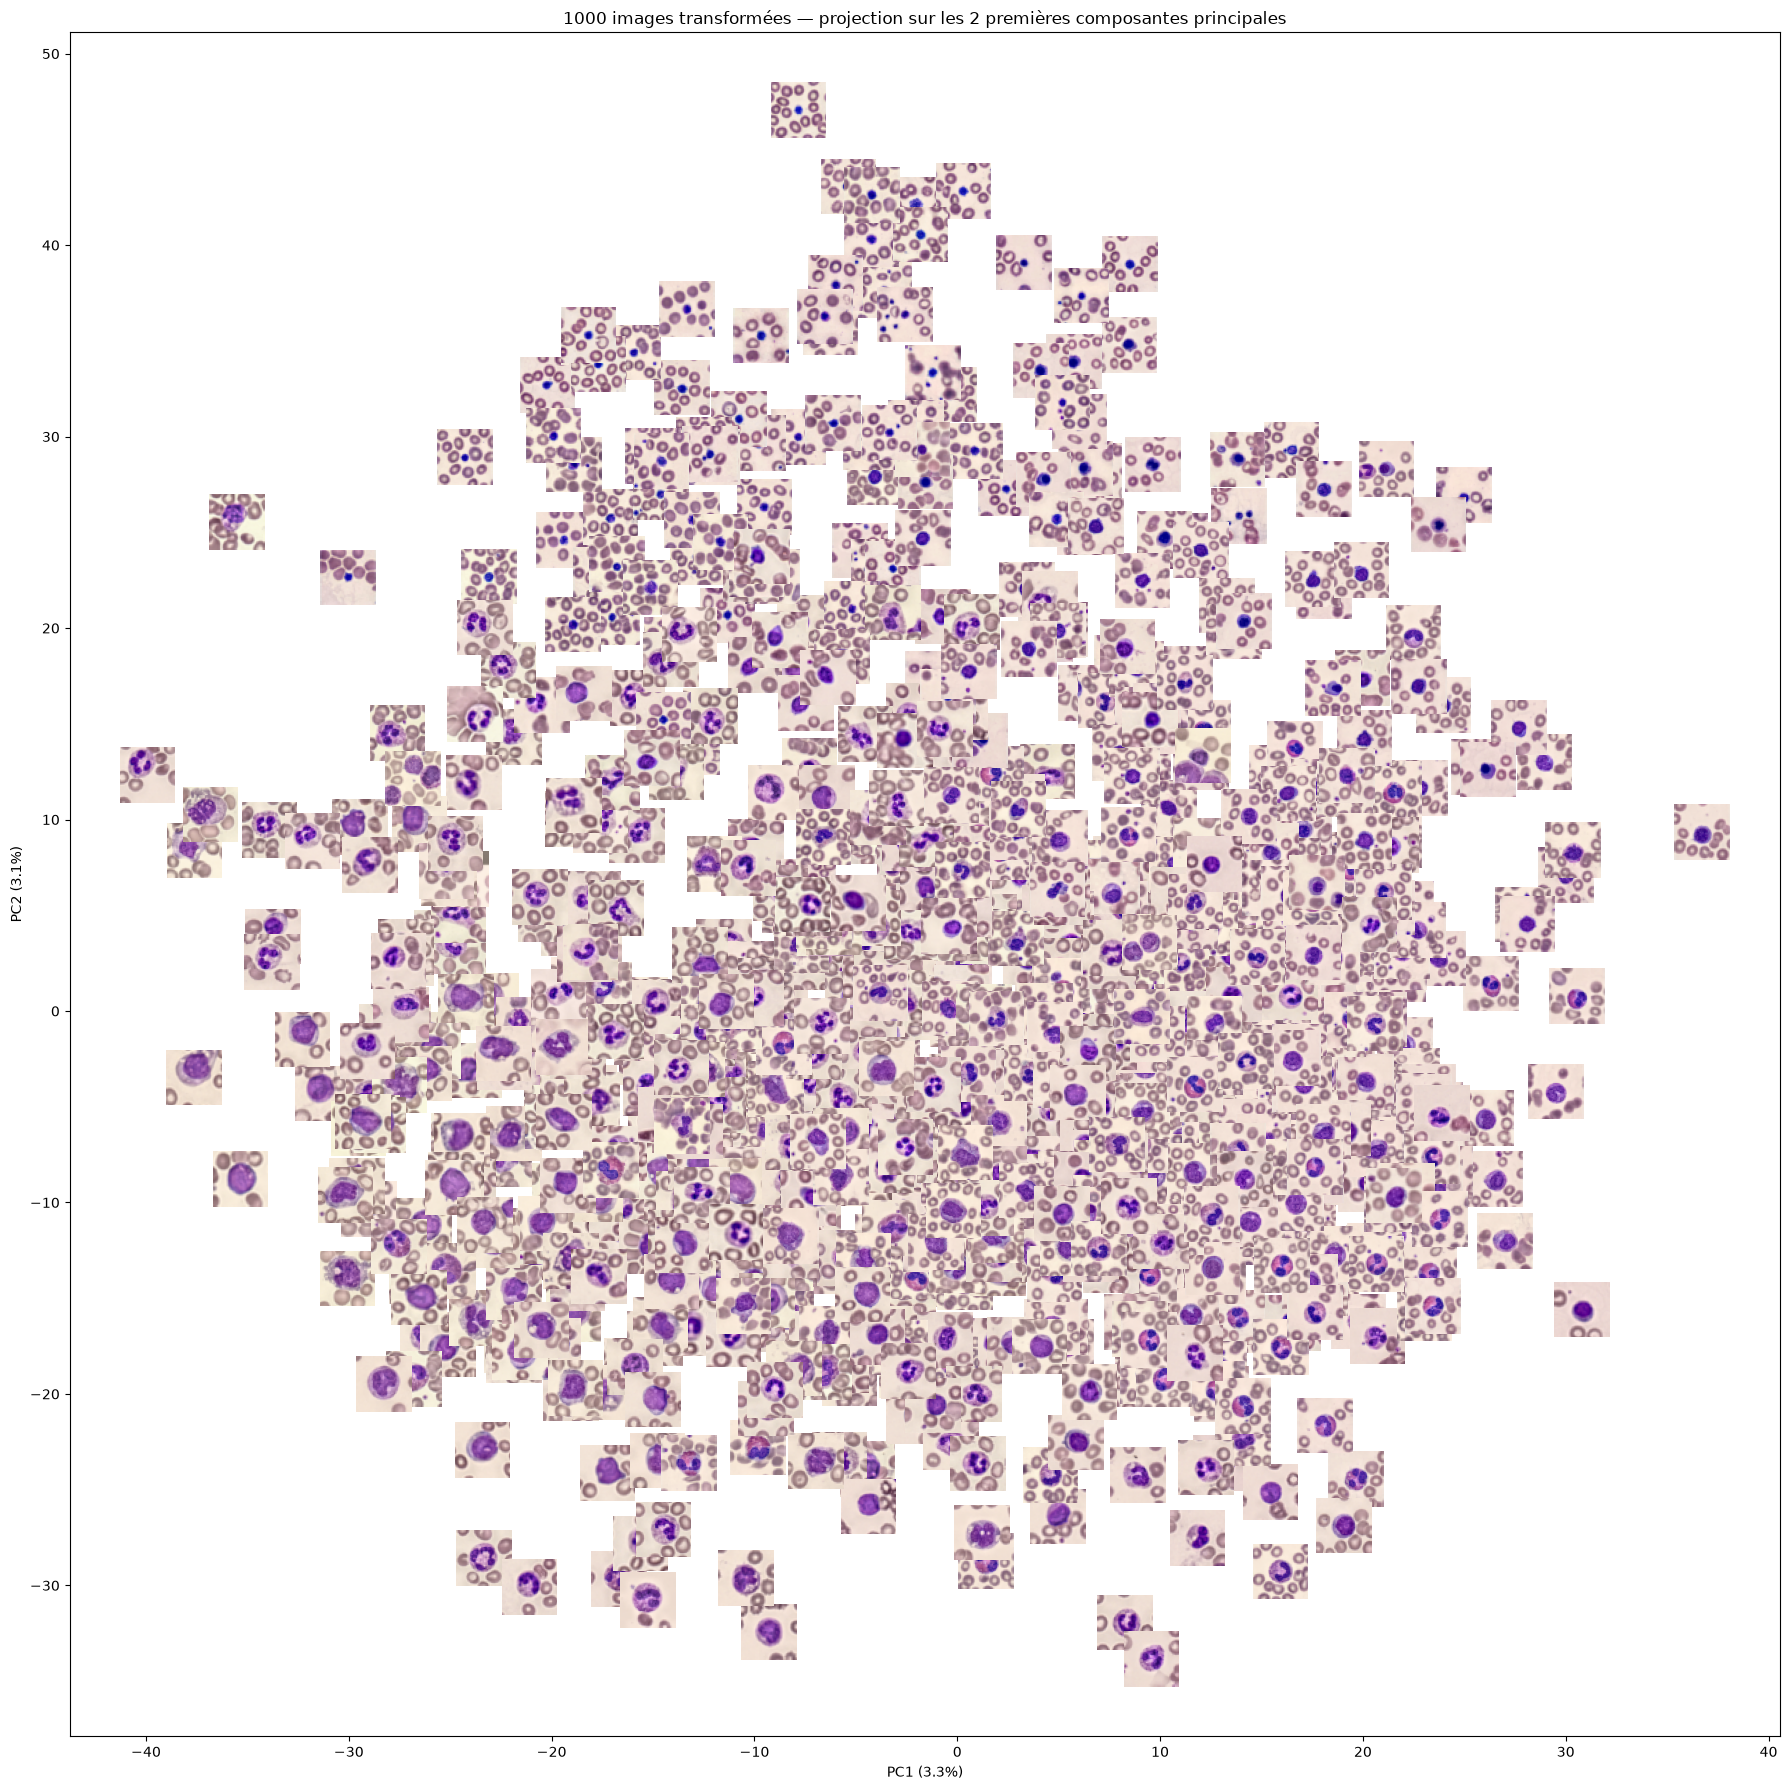

In [ ]:
plot_pca_images(
    coords,
    thumbs,
    pca.explained_variance_ratio_,
    f"{N} images transformées — projection sur les 2 premières composantes principales",
)

### Nuage de points coloré par type / dataset

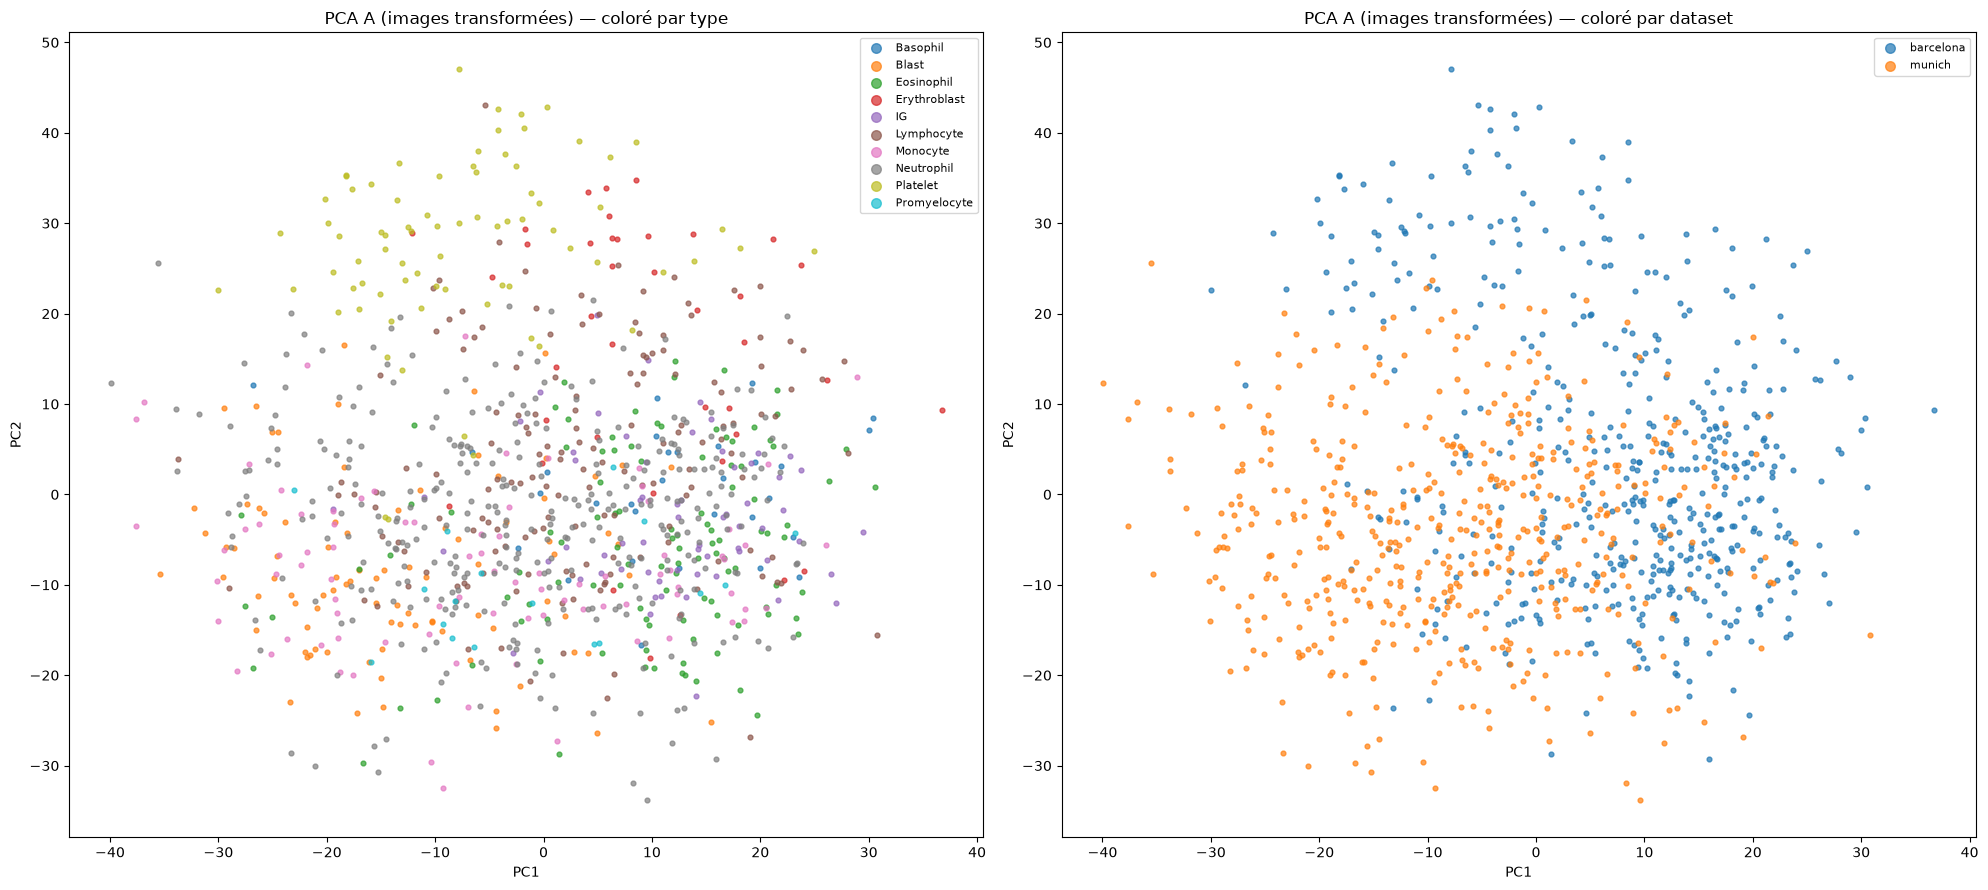

In [9]:
plot_pca_scatter(coords, df, "PCA A (images transformées)")

## 5. PCA B — sans aucune transformation

Mêmes images (même échantillon `df`), mais sans le pipeline : pas de padding, pas de
normalisation colorimétrique, pas de CLAHE, pas de normalisation finale. Seul un
redimensionnement au format carré est appliqué (indispensable pour aplatir les images
en vecteurs de même taille) et une simple mise à l'échelle `[0, 1]`.

In [10]:
X_raw = np.empty((len(df), 3 * PCA_RES * PCA_RES), dtype=np.float32)
thumbs_raw = np.empty((len(df), THUMB_PX, THUMB_PX, 3), dtype=np.uint8)

for i, path in enumerate(tqdm(df["path"], desc="raw")):
    with Image.open(path) as img:
        tensor = v2.functional.pil_to_tensor(img.convert("RGB")).float() / 255.0
    X_raw[i] = v2.functional.resize(tensor, [PCA_RES, PCA_RES], antialias=True).numpy().reshape(-1)
    thumb = v2.functional.resize(tensor, [THUMB_PX, THUMB_PX], antialias=True)
    thumbs_raw[i] = (thumb.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

X_raw.shape

raw: 100%|██████████| 1000/1000 [00:01<00:00, 994.30it/s]


(1000, 12288)

### PCA à 2 composantes

In [11]:
pca_raw, coords_raw = run_pca(X_raw)
coords_raw.shape

variance expliquée : [0.12169822 0.09503163] | cumulée : 0.21672985


(1000, 2)

### Affichage des N images dans le plan des 2 composantes

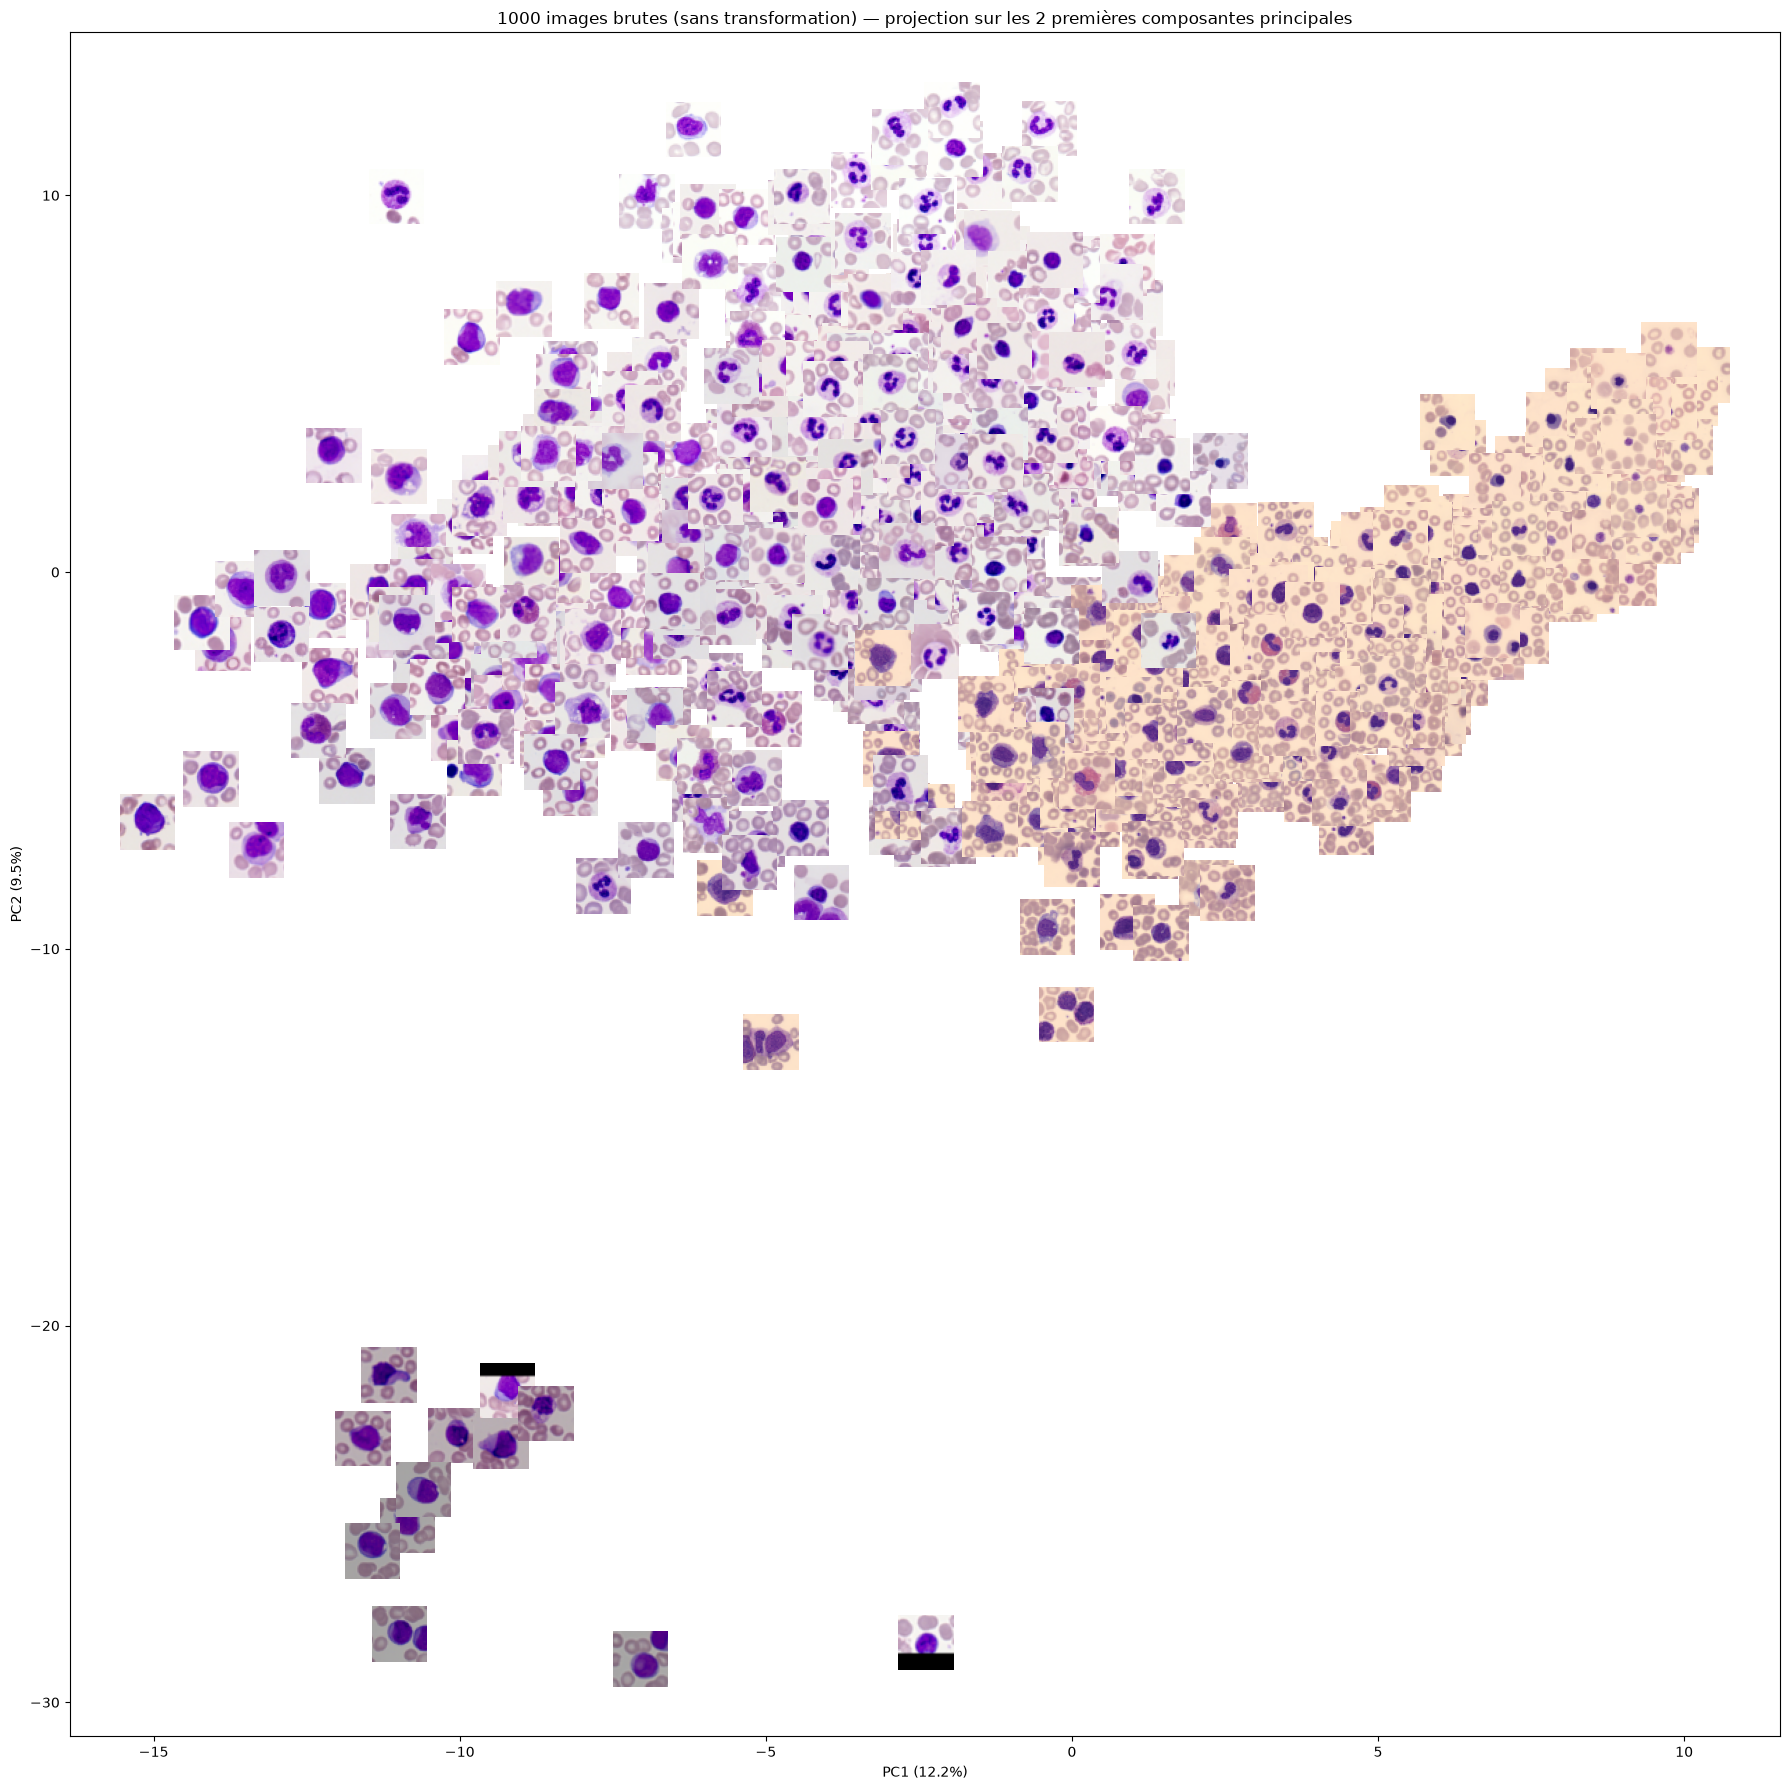

In [ ]:
plot_pca_images(
    coords_raw,
    thumbs_raw,
    pca_raw.explained_variance_ratio_,
    f"{N} images brutes (sans transformation) — projection sur les 2 premières composantes principales",
)

### Nuage de points coloré par type / dataset

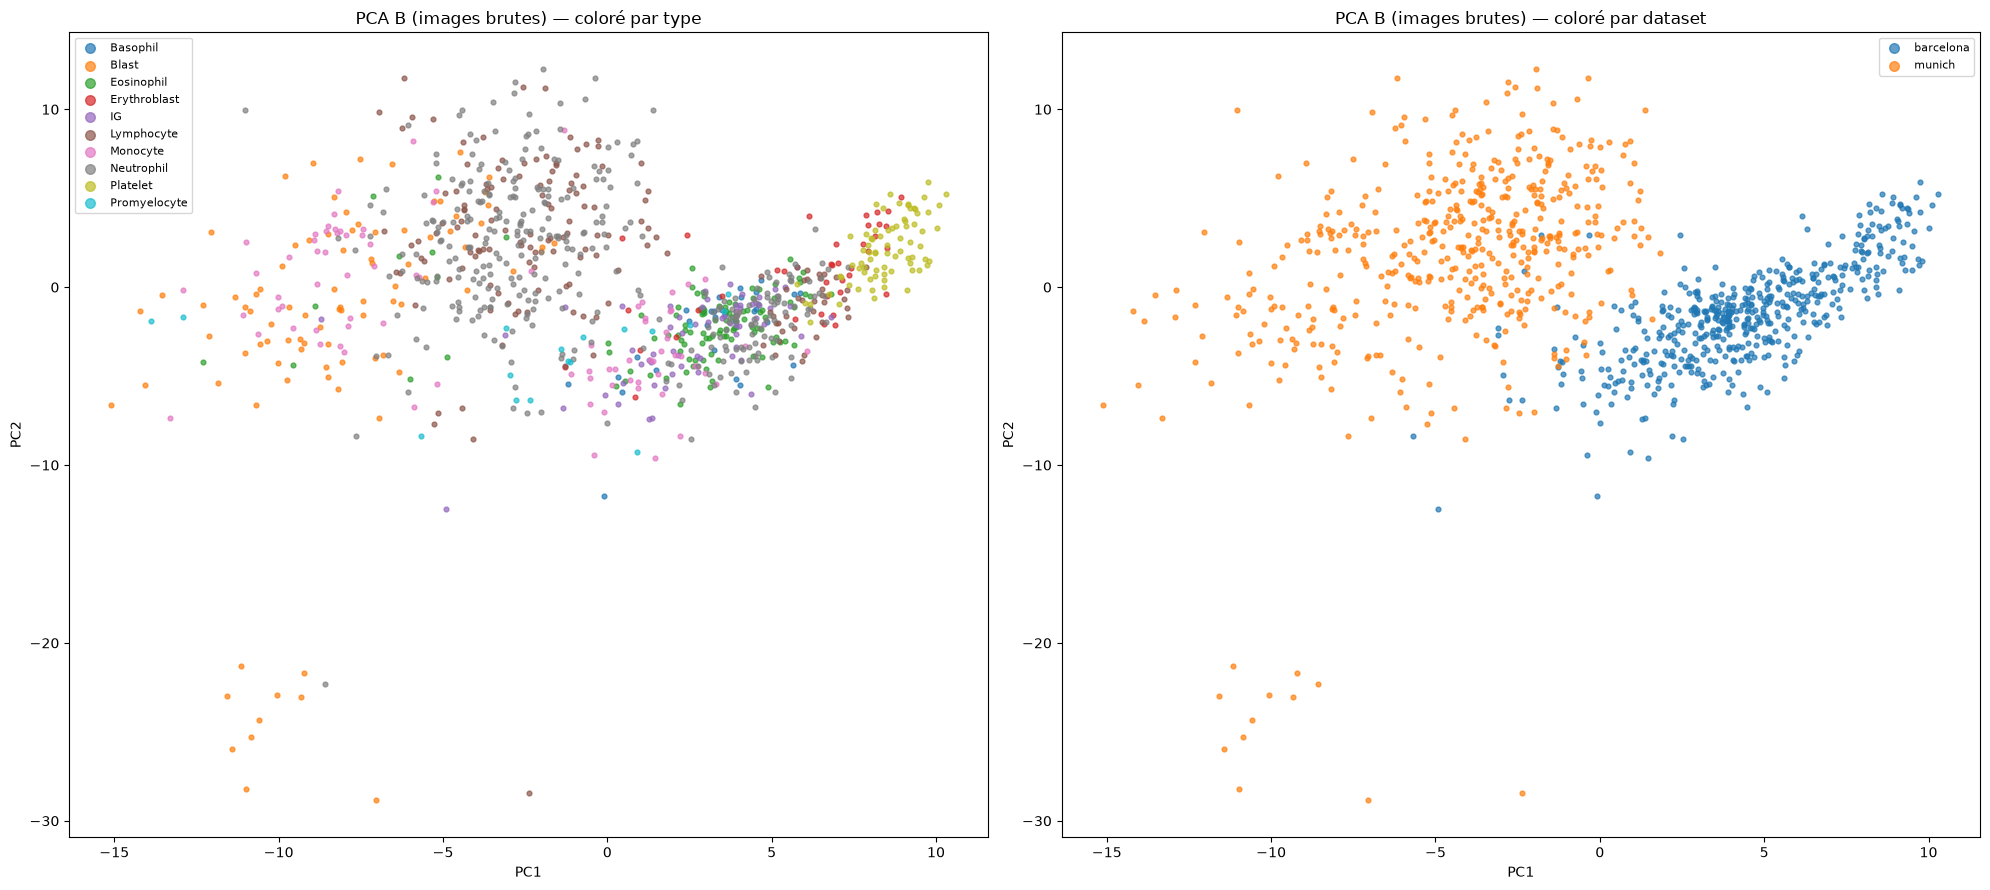

In [13]:
plot_pca_scatter(coords_raw, df, "PCA B (images brutes)")

In [ ]:
def plot_pca_scatter_comp(
    coords_a, coords_b, df, fig_title, titles=["sans transformation", "avec transformation"]
):
    """Nuage de points de la PCA, un subplot par donnée."""
    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    fig.suptitle(fig_title, fontsize=16)
    for ax, coords, title in zip(np.atleast_1d(axes), [coords_a, coords_b], titles):
        for key, sub in df.groupby("dataset"):
            idx = sub.index.to_numpy()
            ax.scatter(coords[idx, 0], coords[idx, 1], s=12, alpha=0.7, label=str(key))
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_title(f"PCA {title}")
        ax.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    plt.show()


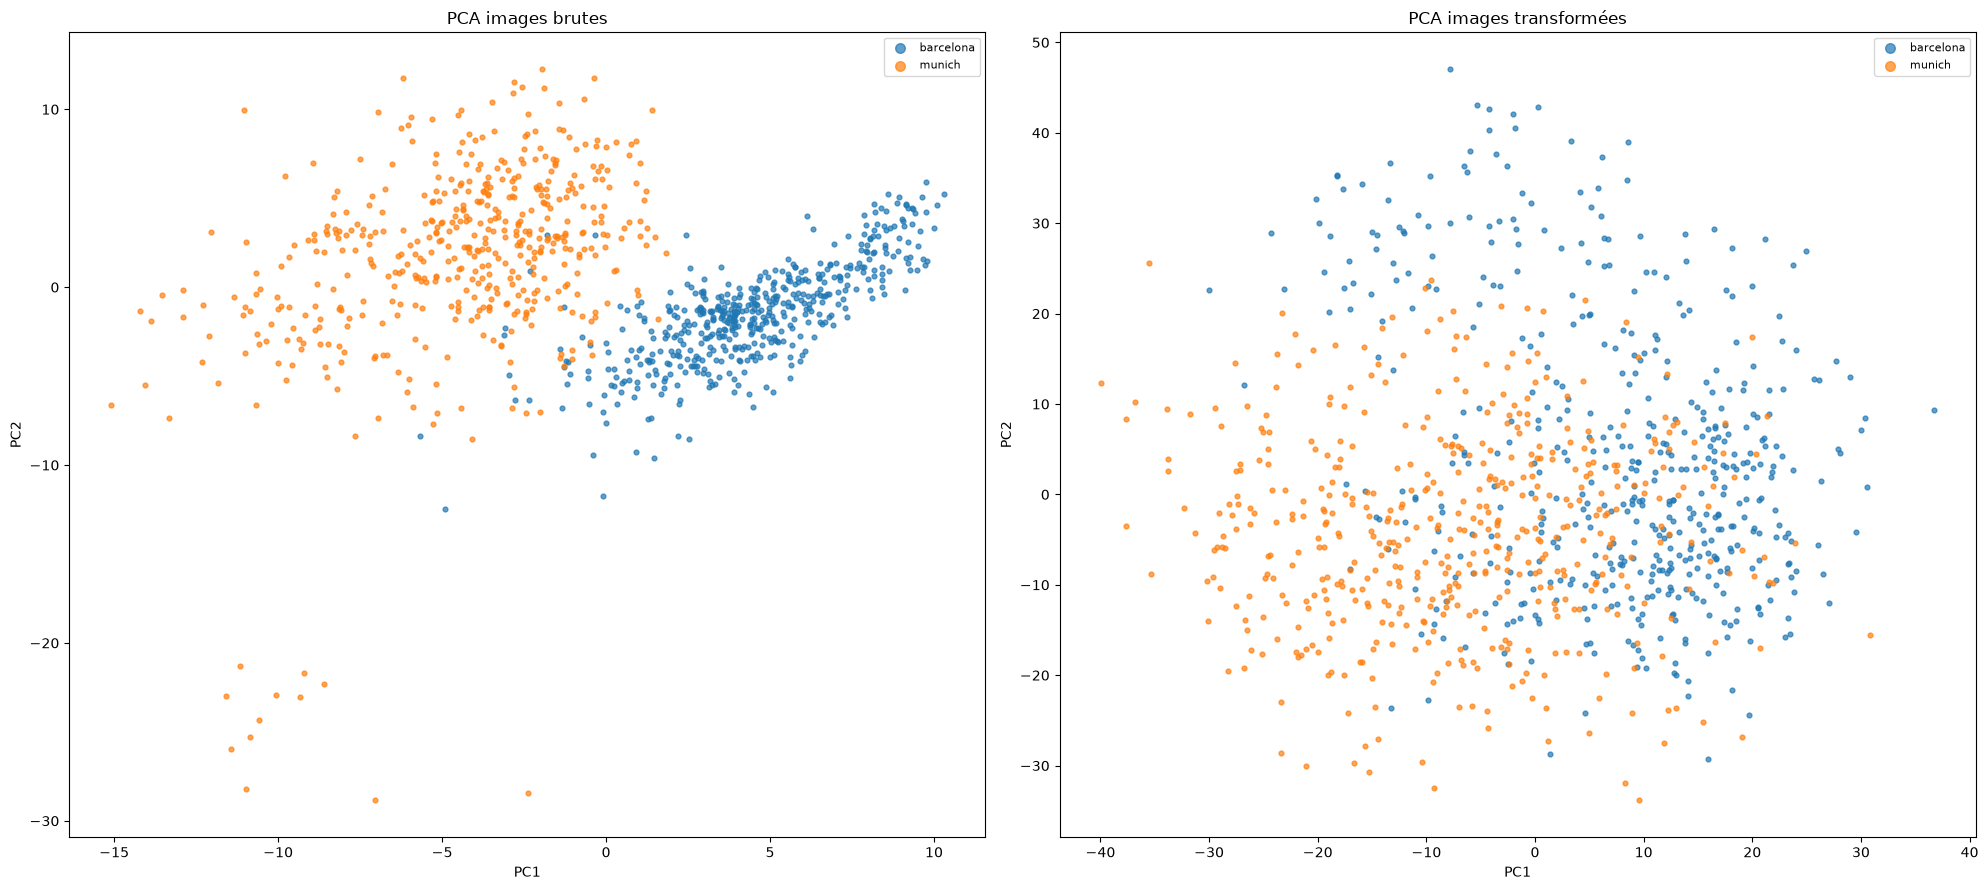

In [ ]:
plot_pca_scatter_comp(
    coords_raw,
    coords,
    df,
    "Comparaison PCA sur les datasets",
    titles=["images brutes", "images transformées"],
)

In [ ]:
import seaborn as sns


def plot_pca_scatter_comp(
    coords_a, coords_b, df, fig_title, titles=["sans transformation", "avec transformation"]
):
    """Nuage de points de la PCA, un subplot par donnée."""
    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    fig.suptitle(fig_title, fontsize=16)
    for ax, coords, title in zip(np.atleast_1d(axes), [coords_a, coords_b], titles):
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["dataset"], ax=ax, s=12, alpha=0.7)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_title(f"PCA {title}")
        ax.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    plt.show()

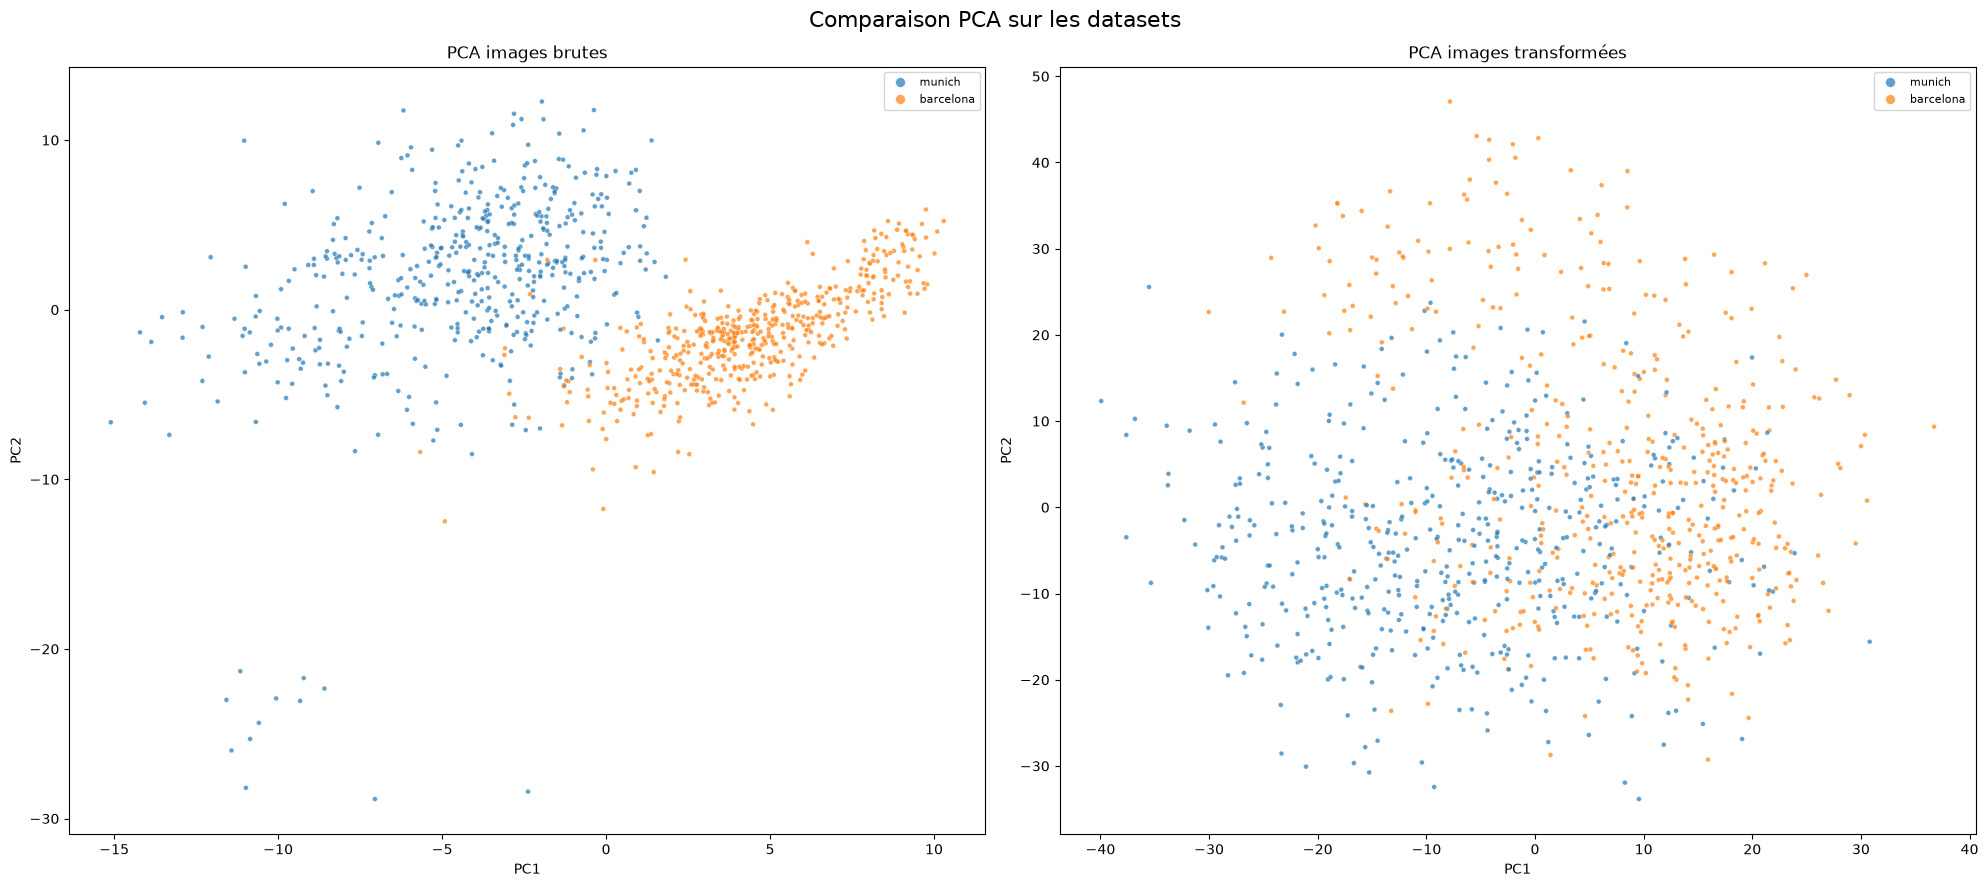

In [ ]:
plot_pca_scatter_comp(
    coords_raw,
    coords,
    df,
    "Comparaison PCA sur les datasets",
    titles=["images brutes", "images transformées"],
)